In [1]:
library(tidyverse)
library(GenomicRanges)
library(edgeR)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Loading required package: stats4

Loading required package: BiocGenerics


Attaching package: ‘BiocGenerics’


The following objects are masked from ‘package:lubridate’:

    intersect, setdiff, union


The following objects are masked from ‘package:dplyr’:

    combine, intersect, setdiff, union


The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs


The following objects are masked from ‘package:base’:

    anyDuplicated, aperm, append, 

In [4]:
theme_set(theme_bw() + theme(rect=element_rect(linewidth=1), text=element_text(size=15)))

In [5]:
#read in chromHMM annotations and convert to GRanges object
HMM <- read.delim("~/projects/poised_enh_manuscript/inputs/cRE/chromHMM/hg38_GM12878HMM_intATAC.bed", sep='\t', header=F)
HMM_gr <- GRanges(seqnames=HMM$V1, ranges=IRanges(start=HMM$V2, end=HMM$V3))
#add SCREEN classification to GRanges object
HMM_gr$type <- HMM$V4

#read in filtered ATAC-seq peaks and generate GRanges object
peaks <- read.delim("~/projects/poised_enh_manuscript/inputs/bed/ATAC_peaks/filtered/consensus_filt_annot.tsv", sep='\t', header=T)
peaks_gr <- GRanges(seqnames=peaks$seqnames, ranges=IRanges(start=peaks$start, end=peaks$end), mcols=peaks[,6:12])

In [6]:
merged_gr <- mergeByOverlaps(peaks_gr, HMM_gr)

`summarise()` has grouped output by 'type'. You can override using the
`.groups` argument.
Warning message:
“Returning more (or less) than 1 row per `summarise()` group was deprecated in
dplyr 1.1.0.
ℹ Please use `reframe()` instead.
ℹ When switching from `summarise()` to `reframe()`, remember that `reframe()`
  always returns an ungrouped data frame and adjust accordingly.”
`summarise()` has grouped output by 'type'. You can override using the
`.groups` argument.


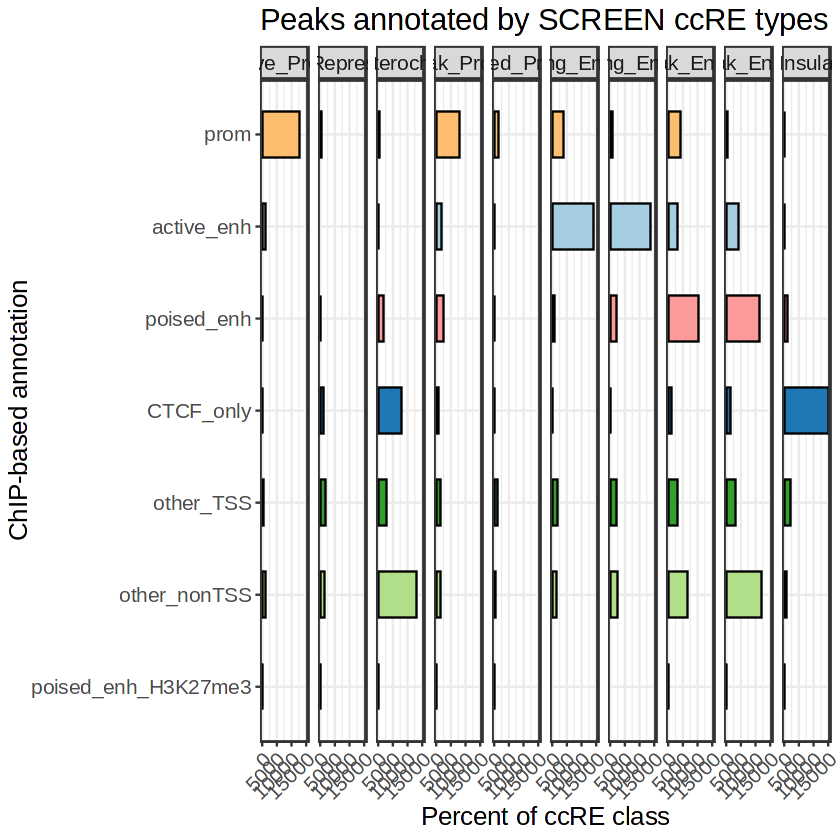

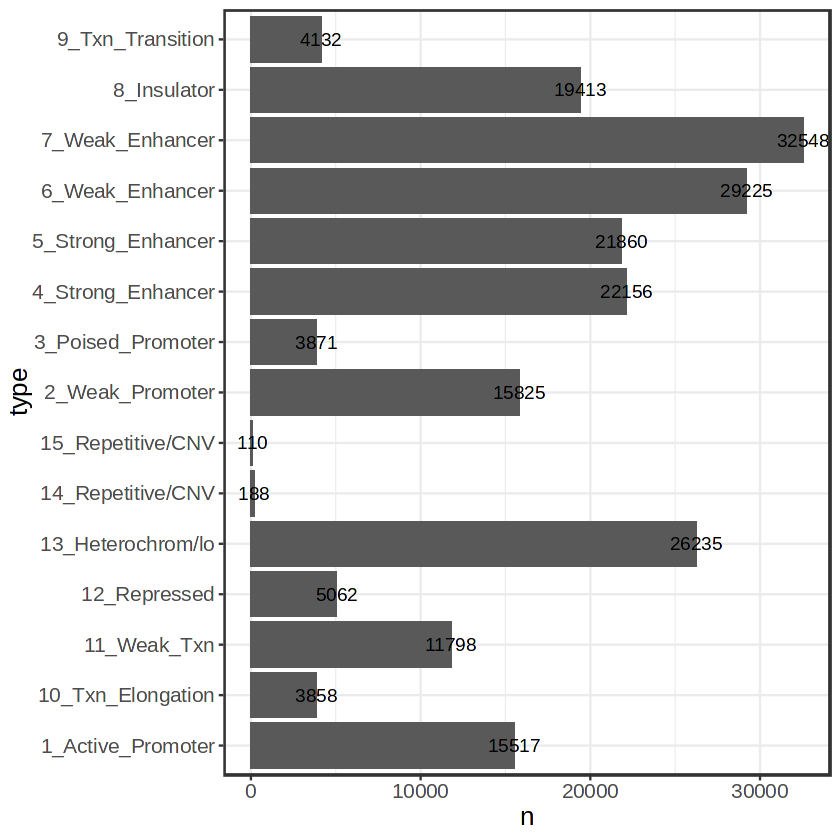

In [25]:
merged_gr %>% data.frame() %>% filter(!grepl("Txn|CNV", type)) %>% group_by(type, mcols.type) %>% summarize(n = n()) %>% ungroup() %>% group_by(type) %>% summarize(n,type, mcols.type, pct=100*n/sum(n)) %>% 
    ggplot(aes(y=factor(mcols.type, levels=rev(c("prom", "active_enh", "poised_enh", "CTCF_only", "other_TSS", "other_nonTSS", "poised_enh_H3K27me3"))), x=n, fill=mcols.type)) + 
        theme(axis.text.x=element_text(angle=45,hjust=1)) +
        geom_col(color="black", show.legend=F, width=.5) + 
        facet_wrap(~type, nrow=1) +
        #facet_wrap(~factor(type, levels=c("PLS", "pELS", "dELS","CA-H3K4me3", "CA-CTCF", "CA-TF", "CA-only")), nrow=1) + 
        ylab("ChIP-based annotation") + 
        xlab("Percent of ccRE class") + ggtitle("Peaks annotated by SCREEN ccRE types") + scale_fill_brewer(palette="Paired")
ggsave("annot_compare.pdf", width=20, height=4)
merged_gr %>% data.frame() %>% group_by(type) %>% summarize(n=n()) %>% ggplot(aes(x=n,y=type)) + geom_col() + geom_text(aes(label=n))

In [26]:
sizes <- colSums(read.delim("../../countmat/brm10uM_6h/invariant_promoters_6h_sort_indexed_counts.tsv",sep='\t',header=F)[,5:10])
cm <- read.delim("~/projects/poised_enh_manuscript/inputs/countmat/brm10uM_6h/hg38_GM12878HMM_intATAC_sort_indexed_counts.tsv",sep='\t',header=F)

In [27]:
counts <- cm[,11:16]
col.data <- data.frame(condition=c("dmso", "dmso", "dmso", "brm", "brm", "brm"))

In [28]:
dge <- DGEList(counts=counts,group=col.data$condition)
dge <- calcNormFactors(dge)
#specify design for analysis (here just comparing treatment to control)
design <- model.matrix(~0+group, data=dge$samples)
dge <- estimateDisp(dge, design)

#this is the key step, where I am calculating normalization factors using the summed counts at invariant promoters as my library sizes
dge$samples$norm.factors <- 1/calcNormFactors(as.matrix(dge), lib.size=sizes)

#run DAR analysis
dge_fit <- glmQLFit(dge)
diff <- glmQLFTest(dge_fit, contrast=c(1,-1))

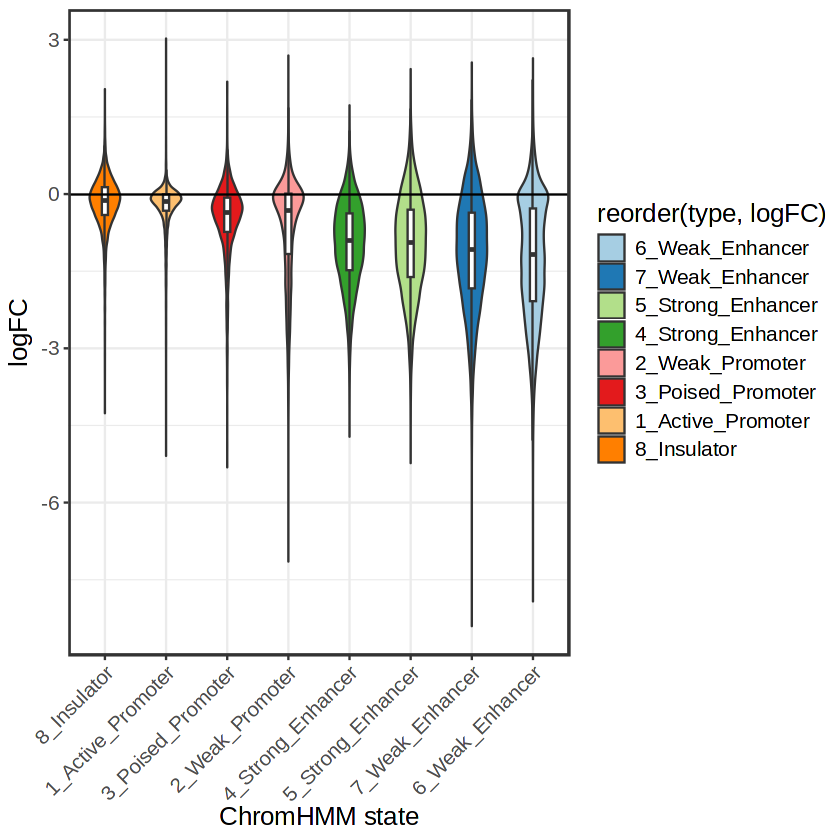

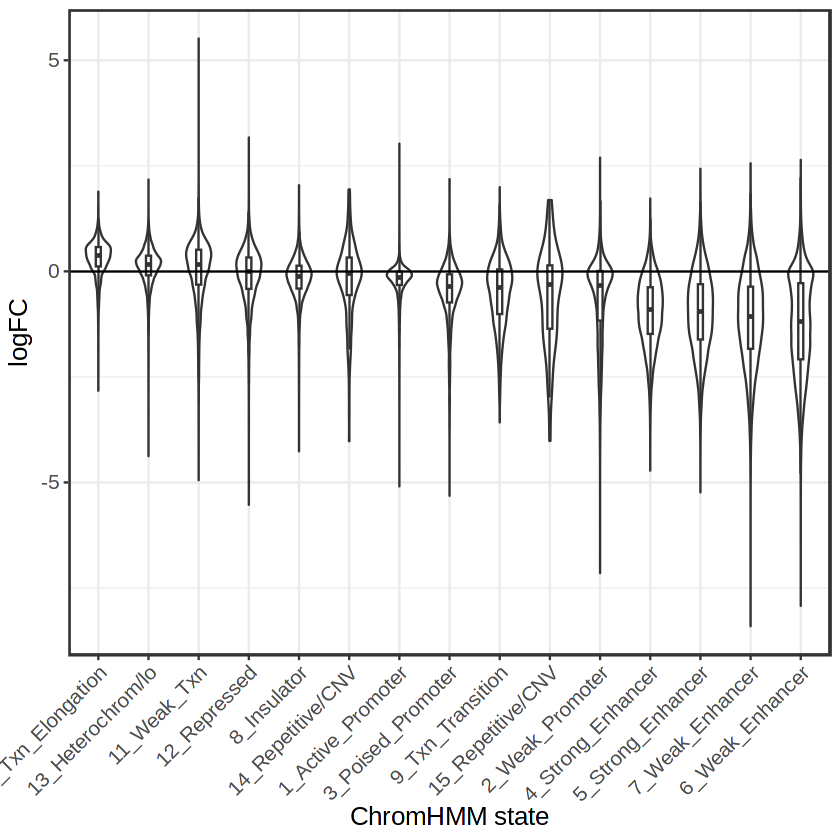

In [46]:
topTags(diff, n=Inf, sort.by="none")$table %>% mutate(type=cm$V4) %>% filter(grepl("Promoter|Enhancer|Insulator", type))  %>% ggplot(aes(fill=reorder(type, logFC),y=logFC, x=reorder(type, -logFC))) + theme(axis.text.x=element_text(angle=45,hjust=1))+
    geom_violin(scale="width", width=.5) + geom_boxplot(fill="white",width=.1, outlier.shape=NA)  + xlab("ChromHMM state") + geom_hline(yintercept=0) + scale_fill_brewer(palette="Paired")

topTags(diff, n=Inf, sort.by="none")$table %>% mutate(type=cm$V4)  %>% ggplot(aes(y=logFC, x=reorder(type, -logFC))) + theme(axis.text.x=element_text(angle=45,hjust=1))+
    geom_violin(scale="width", width=.5) + geom_boxplot(fill="white",width=.1, outlier.shape=NA)  + xlab("ChromHMM state") + geom_hline(yintercept=0)


In [98]:
wilcox.test(res[res$type=="4_Strong_Enhancer",]$logFC, res[res$type=="5_Strong_Enhancer",]$logFC )
wilcox.test(res[res$type=="4_Strong_Enhancer",]$logFC, res[res$type=="6_Weak_Enhancer",]$logFC )
wilcox.test(res[res$type=="4_Strong_Enhancer",]$logFC, res[res$type=="7_Weak_Enhancer",]$logFC )
wilcox.test(res[res$type=="5_Strong_Enhancer",]$logFC, res[res$type=="6_Weak_Enhancer",]$logFC )
wilcox.test(res[res$type=="5_Strong_Enhancer",]$logFC, res[res$type=="7_Weak_Enhancer",]$logFC )
wilcox.test(res[res$type=="6_Weak_Enhancer",]$logFC, res[res$type=="7_Weak_Enhancer",]$logFC )


	Wilcoxon rank sum test with continuity correction

data:  res[res$type == "4_Strong_Enhancer", ]$logFC and res[res$type == "5_Strong_Enhancer", ]$logFC
W = 208142974, p-value = 0.06273
alternative hypothesis: true location shift is not equal to 0



	Wilcoxon rank sum test with continuity correction

data:  res[res$type == "4_Strong_Enhancer", ]$logFC and res[res$type == "6_Weak_Enhancer", ]$logFC
W = 320088800, p-value < 2.2e-16
alternative hypothesis: true location shift is not equal to 0



	Wilcoxon rank sum test with continuity correction

data:  res[res$type == "4_Strong_Enhancer", ]$logFC and res[res$type == "7_Weak_Enhancer", ]$logFC
W = 338263369, p-value < 2.2e-16
alternative hypothesis: true location shift is not equal to 0



	Wilcoxon rank sum test with continuity correction

data:  res[res$type == "5_Strong_Enhancer", ]$logFC and res[res$type == "6_Weak_Enhancer", ]$logFC
W = 335751774, p-value < 2.2e-16
alternative hypothesis: true location shift is not equal to 0



	Wilcoxon rank sum test with continuity correction

data:  res[res$type == "5_Strong_Enhancer", ]$logFC and res[res$type == "7_Weak_Enhancer", ]$logFC
W = 353331194, p-value < 2.2e-16
alternative hypothesis: true location shift is not equal to 0



	Wilcoxon rank sum test with continuity correction

data:  res[res$type == "6_Weak_Enhancer", ]$logFC and res[res$type == "7_Weak_Enhancer", ]$logFC
W = 430291740, p-value < 2.2e-16
alternative hypothesis: true location shift is not equal to 0


In [32]:
res <- topTags(diff, n=Inf, sort.by="none")$table %>% mutate(type=cm$V4) 
res$type2 <- NA
res$type2[res$type]

In [91]:
library(pheatmap)
mat <- data.frame(type=cm$V4,
                  "H3K4me1_bw"=(read.delim("/mnt/disk/home/agulka/projects/poised_enh_manuscript/inputs/bigwig/ENCODE/bwaob/GM12878_chromHMM/H3K4me1.tab",sep='\t', header=F) %>% arrange(V1))$V6,
                  "H3K4me3_bw"=(read.delim("/mnt/disk/home/agulka/projects/poised_enh_manuscript/inputs/bigwig/ENCODE/bwaob/GM12878_chromHMM/H3K4me3.tab",sep='\t', header=F) %>% arrange(V1))$V6,
                  "H3K27ac_bw"=(read.delim("/mnt/disk/home/agulka/projects/poised_enh_manuscript/inputs/bigwig/ENCODE/bwaob/GM12878_chromHMM/H3K27ac.tab",sep='\t', header=F) %>% arrange(V1))$V6,
                  "CTCF_bw"=(read.delim("/mnt/disk/home/agulka/projects/poised_enh_manuscript/inputs/bigwig/ENCODE/bwaob/GM12878_chromHMM/CTCF.tab",sep='\t', header=F) %>% arrange(V1))$V6,
                  "DPF2_bw"=(read.delim("/mnt/disk/home/agulka/projects/poised_enh_manuscript/inputs/bigwig/ENCODE/bwaob/GM12878_chromHMM/DPF2.tab",sep='\t', header=F) %>% arrange(V1))$V6,
                  "MTA2_bw"=(read.delim("/mnt/disk/home/agulka/projects/poised_enh_manuscript/inputs/bigwig/ENCODE/bwaob/GM12878_chromHMM/MTA2.tab",sep='\t', header=F) %>% arrange(V1))$V6,
                  "EP300_bw"=(read.delim("/mnt/disk/home/agulka/projects/poised_enh_manuscript/inputs/bigwig/ENCODE/bwaob/GM12878_chromHMM/EP300.tab",sep='\t', header=F) %>% arrange(V1))$V6) %>% group_by(type) %>% 
    summarize(H3K4me1=mean(H3K4me1_bw), H3K4me3=mean(H3K4me3_bw), H3K27ac=mean(H3K27ac_bw), CTCF=mean(CTCF_bw),  DPF2=mean(DPF2_bw), MTA2=mean(MTA2_bw), EP300=mean(EP300_bw))



type,H3K4me1,H3K4me3,H3K27ac,CTCF,EP300,DPF2
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
10_Txn_Elongation,0.7163035,0.1987096,0.6362476,0.9406638,0.6562479,0.7948855
11_Weak_Txn,0.9254293,0.1999615,0.5358134,0.6052638,0.6775483,0.8192633
12_Repressed,0.7543007,0.4063322,0.2143738,0.8327910,0.7383621,0.8946715
13_Heterochrom/lo,0.4804942,0.1560871,0.2471477,0.5118902,0.6347397,0.7200935
14_Repetitive/CNV,0.7132948,0.8605849,0.5962328,5.2358795,0.6884434,0.8049096
15_Repetitive/CNV,1.4079287,2.5965414,2.4921249,3.3281362,0.9628976,0.8885717
1_Active_Promoter,1.5651334,33.1537229,13.2830921,3.1310160,1.3588915,2.0552502
2_Weak_Promoter,3.3993197,6.9766483,2.3183698,4.7762608,1.3591322,1.7932046
3_Poised_Promoter,2.6796924,3.4047584,0.3851215,3.8503197,1.0502510,1.7117258


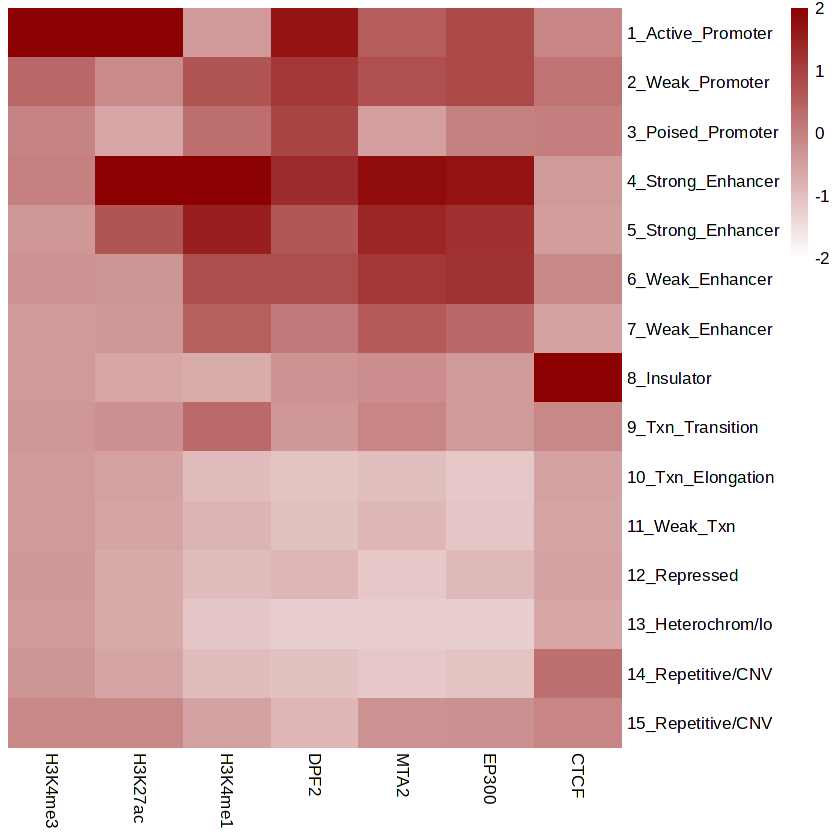

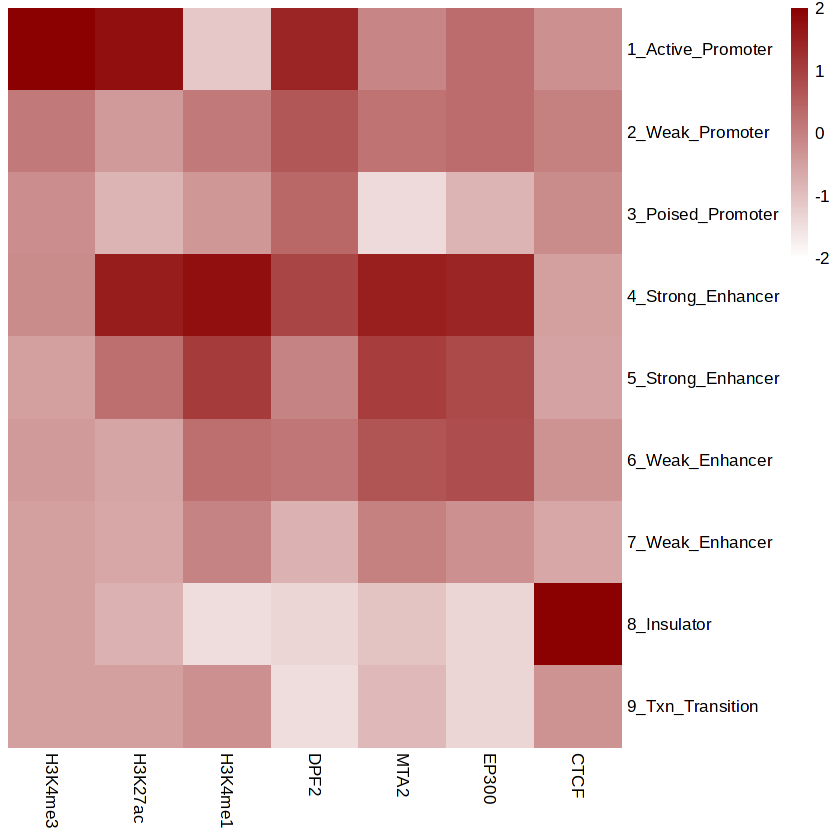

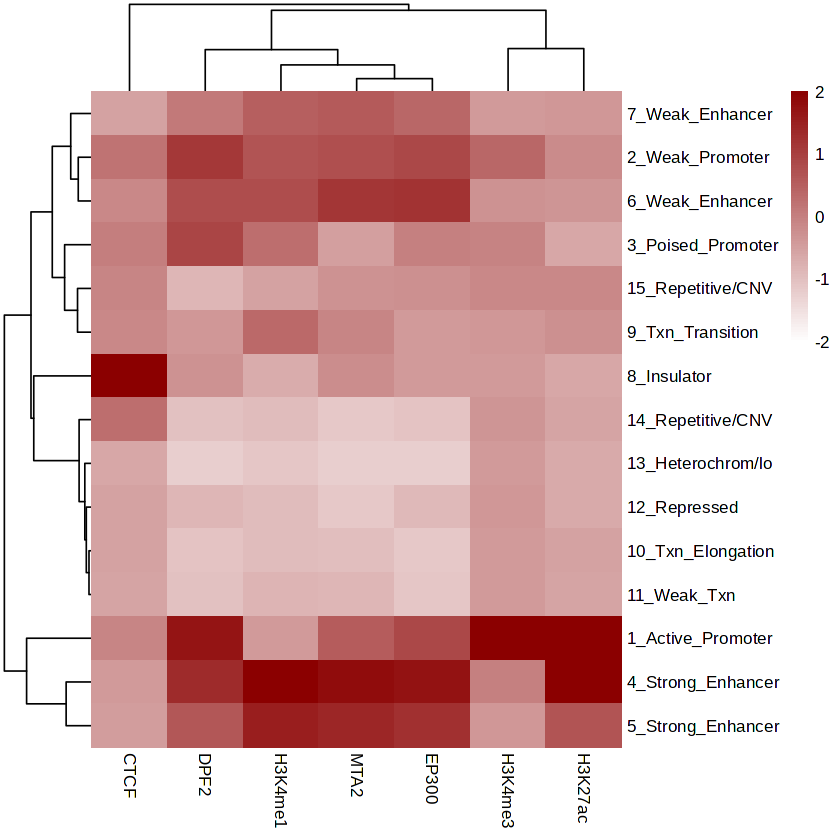

In [92]:
mat[c(7:15, 1:6),c(1,3,4,2,6,7,8,5)] %>% select(!type) %>% pheatmap(scale="column", color=colorRampPalette(colors=c("white", "red4"))(100), cluster_rows=F, cluster_cols=F, labels_row=mat[c(7:15, 1:6),c(1,3,4,2,6,7,5)]$type, breaks=seq(-2,2, length.out=100), border_col=NA)
mat[c(7:15),c(1,3,4,2,6,7,8,5)] %>% select(!type) %>% pheatmap(scale="column", color=colorRampPalette(colors=c("white", "red4"))(100), cluster_rows=F, cluster_cols=F, labels_row=mat[c(7:15),c(1,3,4,2,6,7,5)]$type, breaks=seq(-2,2, length.out=100), border_col=NA)

mat %>% select(!type) %>% pheatmap(scale="column", color=colorRampPalette(colors=c("white", "red4"))(100), cluster_rows=T, cluster_cols=T, labels_row=mat$type, breaks=seq(-2,2, length.out=100), border_col=NA)


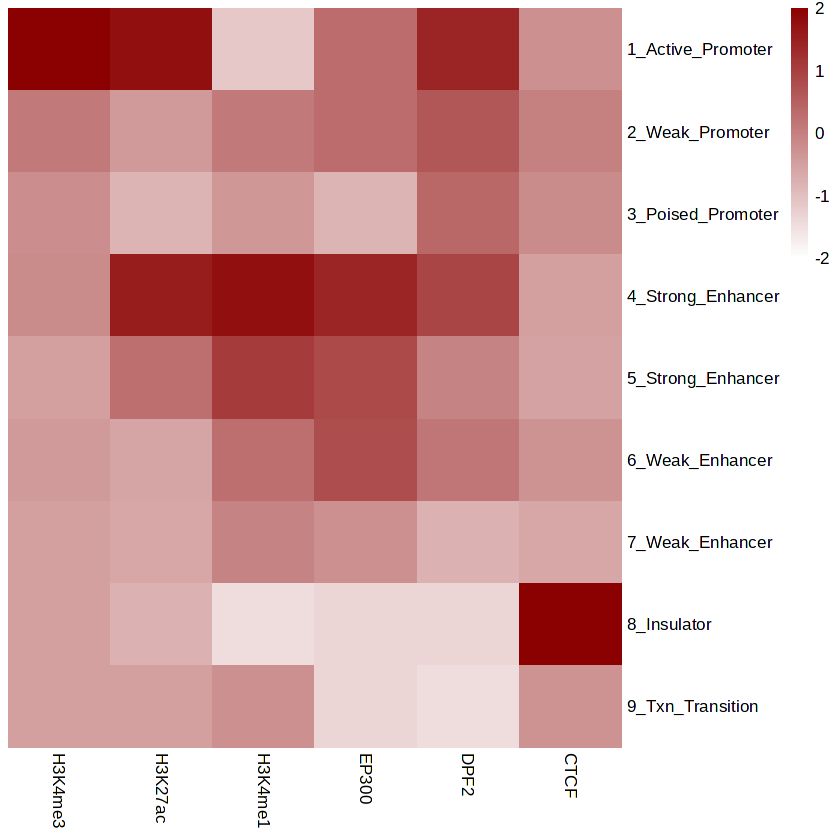

In [86]:
mat[c(7:15),c(1,3,4,2,6,7,8,5)] %>% select(!type) %>% pheatmap(scale="column", color=colorRampPalette(colors=c("white", "red4"))(100), cluster_rows=F, cluster_cols=F, labels_row=mat[c(7:15),c(1,3,4,2,6,7,5)]$type, breaks=seq(-2,2, length.out=100), border_col=NA)


In [85]:
mat[c(7:15),c(1,3,4,2,6,7,5)] 

type,H3K4me3,H3K27ac,H3K4me1,EP300,DPF2,CTCF
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1_Active_Promoter,33.1537229,13.2830921,1.565133,1.3588915,2.055250,3.1310160
2_Weak_Promoter,6.9766483,2.3183698,3.399320,1.3591322,1.793205,4.7762608
3_Poised_Promoter,3.4047584,0.3851215,2.679692,1.0502510,1.711726,3.8503197
4_Strong_Enhancer,3.6895384,12.2978808,5.739744,1.6626837,1.893388,1.6204760
5_Strong_Enhancer,0.6152920,5.7865848,4.744213,1.4957707,1.577628,1.3549683
6_Weak_Enhancer,1.2098541,1.5829159,3.580777,1.4820274,1.642884,2.9518550
7_Weak_Enhancer,0.2754863,1.3339995,3.132111,1.1997755,1.330883,0.8849561
8_Insulator,0.2245425,0.3943845,1.118824,0.9125967,1.153605,21.9144671
9_Txn_Transition,0.4120831,1.8950450,2.824957,0.9075596,1.105213,2.9425505
